# **LINEAR GRESSION**

**1. Import thư viện và đọc dữ liệu**

In [ ]:
# Import thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Kết nối Google Drive để đọc file dữ liệu
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Đọc dữ liệu
X_train = pd.read_csv(f"/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_train.csv")
X_test  = pd.read_csv(f"/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_test.csv")
# Dùng .squeeze() để chuyển y về dạng Series (mảng 1 chiều) chuẩn
y_train = pd.read_csv(f"/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_train.csv").squeeze()
y_test  = pd.read_csv(f"/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_test.csv").squeeze()

# Kiểm tra nhanh
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (25970, 20)
X_test shape : (6493, 20)
y_train shape: (25970,)
y_test shape : (6493,)


In [ ]:
# Kiểm tra lại các cột hiện có để phân loại
print(X_train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25970 entries, 0 to 25969
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   delivery_person_age      25970 non-null  float64
 1   delivery_person_ratings  25970 non-null  float64
 2   vehicle_condition        25970 non-null  int64  
 3   type_of_order            25970 non-null  object 
 4   type_of_vehicle          25970 non-null  object 
 5   multiple_deliveries      25970 non-null  float64
 6   festival                 25970 non-null  object 
 7   is_weekend               25970 non-null  int64  
 8   prep_time                25970 non-null  float64
 9   distance_km              25970 non-null  float64
 10  weather_traffic          25970 non-null  object 
 11  traffic_city             25970 non-null  object 
 12  hour_sin                 25970 non-null  float64
 13  hour_cos                 25970 non-null  float64
 14  dow_sin               

**2. Tiền xử lý riêng (Encoding & Scaling)**

In [ ]:
# 1. Phân loại biến
# Các cột dạng số (Numerical) cần chuẩn hóa
num_cols = [
    'delivery_person_age', 'delivery_person_ratings', 'prep_time',
    'distance_km', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
    'month_sin', 'month_cos', 'prev_time_taken', 'rolling_avg_city'
]

# Các cột dạng phân loại (Categorical) cần One-Hot Encoding
cat_cols = [
    'type_of_order', 'type_of_vehicle', 'festival', 'weather_traffic',
    'traffic_city', 'vehicle_condition', 'multiple_deliveries', 'is_weekend'
]

print(f"Số lượng biến số: {len(num_cols)}")
print(f"Số lượng biến phân loại: {len(cat_cols)}")

Số lượng biến số: 12
Số lượng biến phân loại: 8


In [ ]:
# 2. Thiết lập pipeline xử lý
# Xử lý biến số: Scaler
scaler = StandardScaler()

# Xử lý biến phân loại: One-Hot Encoder
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

# Gom lại bằng ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', scaler, num_cols),
        ('cat', encoder, cat_cols)
    ],
    verbose_feature_names_out=False
)

# Fit và Transform trên tập Train
X_train_processed = preprocessor.fit_transform(X_train)

# Chỉ Transform trên tập Test
X_test_processed = preprocessor.transform(X_test)

# Chuyển về DataFrame để dễ nhìn
feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_processed, columns=feature_names)
X_test_df = pd.DataFrame(X_test_processed, columns=feature_names)

print("Dữ liệu sau khi xử lý xong cho Linear Regression:")
X_train_df.head()

Dữ liệu sau khi xử lý xong cho Linear Regression:


,delivery_person_age,delivery_person_ratings,prep_time,distance_km,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,...,traffic_city_Low_Urban,traffic_city_Medium_Metropolitian,traffic_city_Medium_Semi-Urban,traffic_city_Medium_Urban,vehicle_condition_1,vehicle_condition_2,multiple_deliveries_1.0,multiple_deliveries_2.0,multiple_deliveries_3.0,is_weekend_1
0,0.595201,0.848551,-1.211820,-1.200378,2.36328,-0.915101,-0.589103,-1.228074,-2.169433,2.169433,...,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,0.421409,-1.069644,0.014736,-1.456039,2.36328,-0.915101,-0.589103,-1.228074,-2.169433,2.169433,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.316506,-1.069644,0.014736,-1.457461,2.36328,-0.915101,-0.589103,-1.228074,-2.169433,2.169433,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.099965,0.848551,1.241291,-1.171932,2.36328,-0.915101,-0.589103,-1.228074,-2.169433,2.169433,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1.116576,0.528852,-1.211820,-1.166302,2.36328,-0.915101,-0.589103,-1.228074,-2.169433,2.169433,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


**3. Xây dựng và huấn luyện**

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_df, y_train)

print("Đã huấn luyện xong mô hình!")
print("Intercept (Hệ số tự do):", lr_model.intercept_)
print("Coefficients (Hệ số hồi quy):", lr_model.coef_)

Đã huấn luyện xong mô hình!
Intercept (Hệ số tự do): 32.183094037587644
Coefficients (Hệ số hồi quy): [ 2.26277112e+00 -2.15186454e+00 -1.56506448e-03  1.83836818e+00
  3.57763096e-01 -1.65419937e-01 -2.74112290e-03  1.52086828e-02
 -5.35007603e-03  5.35007603e-03  5.24033760e-02  6.72866167e-01
 -1.57537461e-02  8.53389198e-03  5.58285759e-02  1.33461695e-02
  3.77293093e-02  7.99904969e+00  5.41039362e+00 -7.16496997e+00
 -2.37337582e+00 -6.01167327e-01  5.77458084e+00 -7.12671913e+00
 -2.37381135e+00 -1.51191850e+00 -4.80975285e-01 -8.58598886e+00
 -2.83664783e+00 -1.52191494e+00 -4.15503445e-01 -8.29957549e+00
 -3.27296277e+00 -5.98025978e+00 -5.87224667e+00 -8.02760951e+00
 -9.32047133e+00 -1.80040802e+00 -3.57591596e-01 -8.46608747e+00
 -2.74907633e+00  1.13458720e+01 -1.79538885e+00 -1.90652166e+00
  4.49734116e+00 -2.90019072e+00  1.80162451e-01 -1.13552121e+00
  3.22047629e-01  8.63301982e+00 -1.38704310e+00 -4.65611947e+00
 -4.60368238e+00  1.66699006e+00  7.06702758e+00  1.1

**4. Đánh giá mô hình**

In [ ]:
# 1. Dự báo và đánh giá
y_pred_train = lr_model.predict(X_train_df)
y_pred_test = lr_model.predict(X_test_df)

def evaluate_model(y_true, y_pred, dataset_name="Data"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"--- Đánh giá trên tập {dataset_name} ---")
    print(f"MAE  (Sai số tuyệt đối trung bình): {mae:.4f} phút")
    print(f"RMSE (Căn bậc hai sai số TB)     : {rmse:.4f} phút")
    print(f"R2 Score (Độ phù hợp)            : {r2:.4f}")
    print("-" * 30)

evaluate_model(y_train, y_pred_train, "TRAIN")
evaluate_model(y_test, y_pred_test, "TEST")

--- Đánh giá trên tập TRAIN ---
MAE  (Sai số tuyệt đối trung bình): 4.4302 phút
RMSE (Căn bậc hai sai số TB)     : 5.5520 phút
R2 Score (Độ phù hợp)            : 0.6500
------------------------------
--- Đánh giá trên tập TEST ---
MAE  (Sai số tuyệt đối trung bình): 4.4036 phút
RMSE (Căn bậc hai sai số TB)     : 5.5696 phút
R2 Score (Độ phù hợp)            : 0.6519
------------------------------


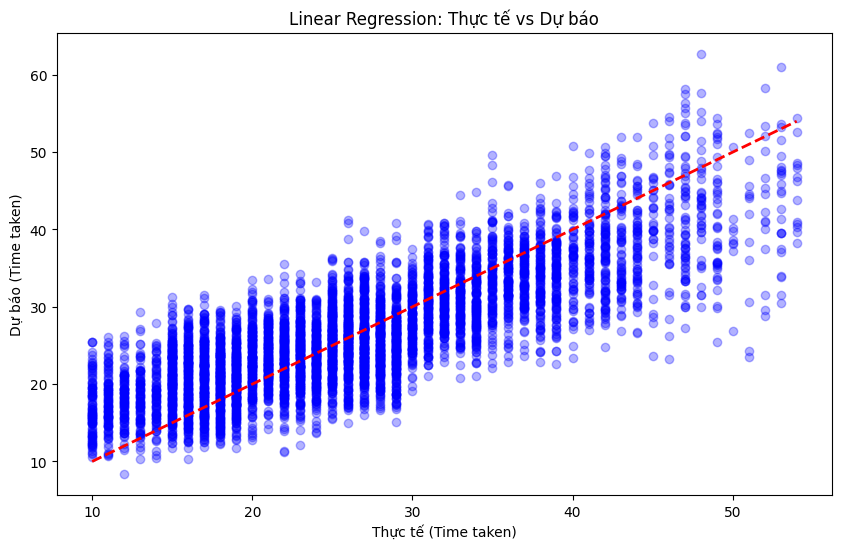

In [ ]:
# 2. Vẽ biểu đồ so sánh thực tế vs dự báo (trên tập Test)
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_test, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Đường chéo chuẩn
plt.xlabel('Thực tế (Time taken)')
plt.ylabel('Dự báo (Time taken)')
plt.title('Linear Regression: Thực tế vs Dự báo')
plt.show()

**5. Tinh chỉnh**

In [ ]:
# 1. Tinh chỉnh với Ridge Regression (L2 Regularization)
# Ridge giúp giảm nhẹ trọng số của các biến không quan trọng (nhưng không về 0)

ridge_model = Ridge(alpha=1.0) # alpha càng lớn thì phạt càng mạnh
ridge_model.fit(X_train_df, y_train)

y_pred_test_ridge = ridge_model.predict(X_test_df)

print("=== KẾT QUẢ RIDGE REGRESSION ===")
evaluate_model(y_test, y_pred_test_ridge, "TEST (Ridge)")

=== KẾT QUẢ RIDGE REGRESSION ===
--- Đánh giá trên tập TEST (Ridge) ---
MAE  (Sai số tuyệt đối trung bình): 4.4038 phút
RMSE (Căn bậc hai sai số TB)     : 5.5703 phút
R2 Score (Độ phù hợp)            : 0.6519
------------------------------


In [ ]:
# 2. Tinh chỉnh với Lasso Regression (L1 Regularization)
# Lasso có thể đưa trọng số về 0 -> Giúp chọn lọc biến quan trọng
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_df, y_train)

y_pred_test_lasso = lasso_model.predict(X_test_df)

print("=== KẾT QUẢ LASSO REGRESSION ===")
evaluate_model(y_test, y_pred_test_lasso, "TEST (Lasso)")

=== KẾT QUẢ LASSO REGRESSION ===
--- Đánh giá trên tập TEST (Lasso) ---
MAE  (Sai số tuyệt đối trung bình): 4.7575 phút
RMSE (Căn bậc hai sai số TB)     : 5.9995 phút
R2 Score (Độ phù hợp)            : 0.5961
------------------------------


**6. Phân tích hệ số hồi quy (Feature Importance)**

/tmp/ipykernel_1095/1028911052.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_positive, x='Coefficient', y='Feature', palette='Reds_r')


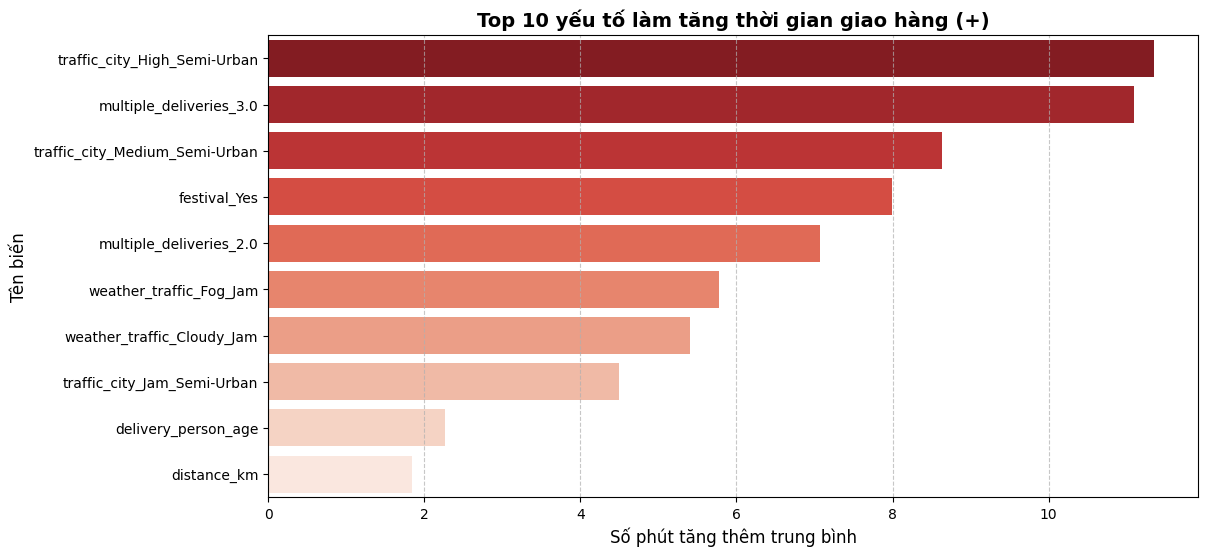

In [ ]:
# Biểu đồ 1: Yếu tố làm tăng thời gian
# Lấy tên các cột sau khi One-Hot Encoding từ preprocessor
feature_names = preprocessor.get_feature_names_out()

# Tạo DataFrame chứa tên biến và hệ số tương ứng từ model Linear Regression (lr_model)
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_
})

# Lấy ra 10 biến làm tăng thời gian nhiều nhất (Hệ số dương lớn nhất)
top_positive = coef_df.sort_values(by='Coefficient', ascending=False).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(data=top_positive, x='Coefficient', y='Feature', palette='Reds_r')

plt.title('Top 10 yếu tố làm tăng thời gian giao hàng (+)', fontsize=14, fontweight='bold')
plt.xlabel('Số phút tăng thêm trung bình', fontsize=12)
plt.ylabel('Tên biến', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_1095/3708119492.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_negative, x='Coefficient', y='Feature', palette='Greens_r')


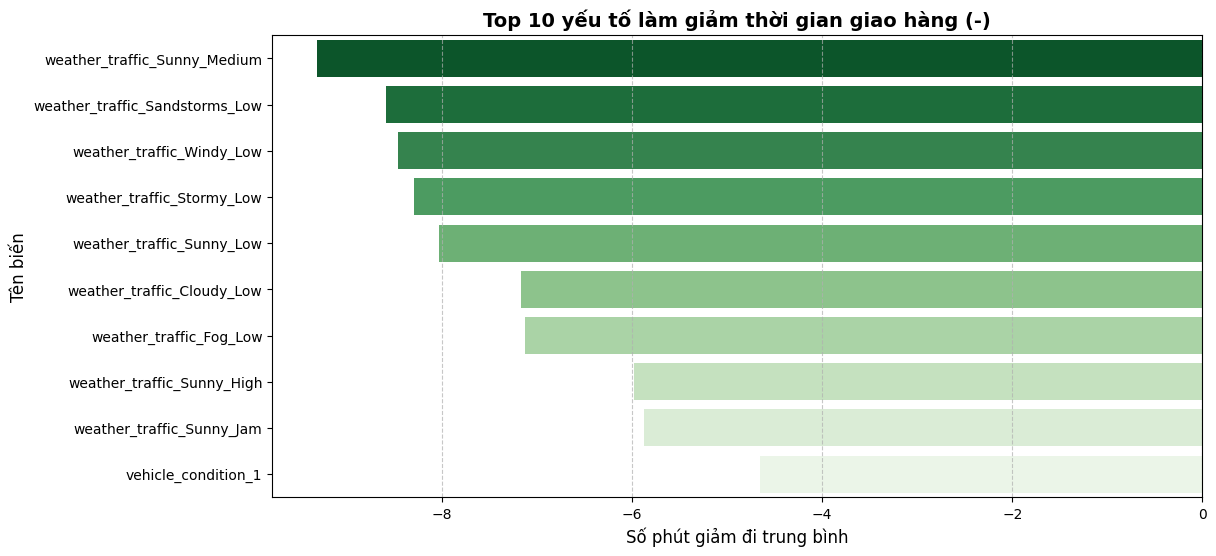

In [ ]:
# Biểu đồ 2: Yếu tố làm giảm thời gian
# Lấy ra 10 biến làm giảm thời gian nhiều nhất (Hệ số âm nhỏ nhất)
top_negative = coef_df.sort_values(by='Coefficient', ascending=True).head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
sns.barplot(data=top_negative, x='Coefficient', y='Feature', palette='Greens_r')
plt.title('Top 10 yếu tố làm giảm thời gian giao hàng (-)', fontsize=14, fontweight='bold')
plt.xlabel('Số phút giảm đi trung bình', fontsize=12)
plt.ylabel('Tên biến', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

**7. Phân tích sai số (Residual Analysis)**

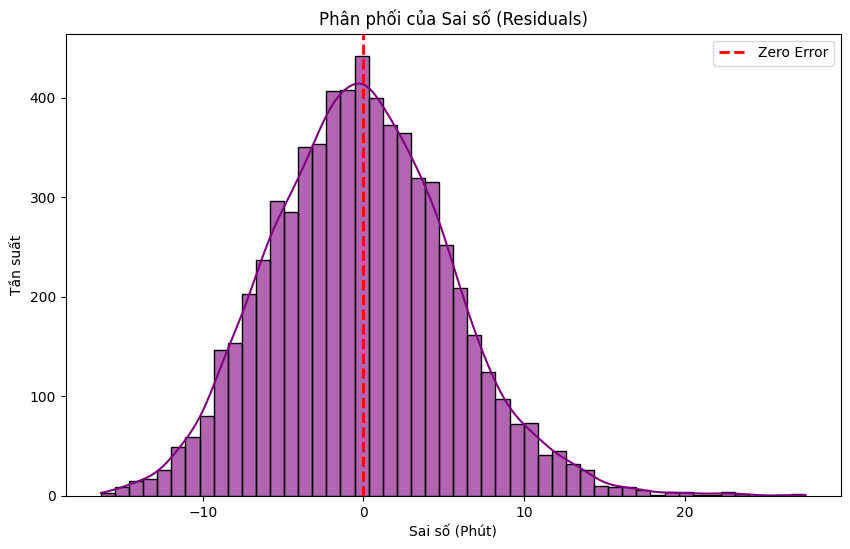

Trung bình sai số (Mean Residual): -0.1160
Độ lệch chuẩn sai số (Std Residual): 5.5688


In [ ]:
# Tính sai số trên tập Test của mô hình Linear Regression gốc
# Residual = Thực tế - Dự báo
residuals = y_test - y_pred_test

plt.figure(figsize=(10, 6))

# Vẽ biểu đồ phân phối của sai số
sns.histplot(residuals, kde=True, bins=50, color='purple', alpha=0.6)

# Vẽ đường trung tâm tại 0
plt.axvline(x=0, color='red', linestyle='--', lw=2, label='Zero Error')

plt.title('Phân phối của Sai số (Residuals)')
plt.xlabel('Sai số (Phút)')
plt.ylabel('Tần suất')
plt.legend()
plt.show()

# Thống kê nhanh về sai số
print(f"Trung bình sai số (Mean Residual): {residuals.mean():.4f}")
print(f"Độ lệch chuẩn sai số (Std Residual): {residuals.std():.4f}")

In [ ]:
import joblib

# 1. Lưu mô hình Linear Regression
joblib.dump(lr_model, '/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/linear_regression_model.pkl')

# 2. Lưu bộ tiền xử lý (Preprocessor)
# Nếu không lưu cái này, sau này có dữ liệu mới bạn sẽ không biết cách One-Hot/Scale y hệt như lúc train
joblib.dump(preprocessor, '/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/preprocessor.pkl')

print("Đã lưu Linear Regression Model và Preprocessor thành công!")

Đã lưu Linear Regression Model và Preprocessor thành công!
